# PriceFusion V0.2 — Deep Exploratory Data Analysis

**Project:** PriceFusion — Multimodal Product Price Intelligence  
**Stage:** V0.2  
**Goal:** Understand the pricing target, catalog structure, train/test similarity, duplicated products, units, quantity signals, and image reuse before modeling.

This notebook covers:
- Dataset overview
- Price and log-price analysis
- Price buckets and outliers
- Train/test text-distribution comparison
- Parsing `Item Name`, `Value`, and `Unit`
- Pack quantity extraction
- Unit-frequency and price analysis
- Numeric text features
- Duplicate catalog analysis
- Image reuse and train/test shared-image analysis
- Feature/price relationships
- EDA artifact and figure generation


## 1. Imports

In [1]:
from pathlib import Path
from urllib.parse import urlparse
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_colwidth', 200)
print('EDA environment ready.')


EDA environment ready.


## 2. Resolve Project Paths

In [2]:
cwd = Path.cwd().resolve()
if (cwd / 'dataset').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'dataset').exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError('Could not find dataset/. Launch Jupyter from PriceFusion/ or PriceFusion/notebooks/.')

DATASET_DIR = PROJECT_ROOT / 'dataset'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
EDA_DIR = ARTIFACTS_DIR / 'eda'
FIGURES_DIR = ARTIFACTS_DIR / 'figures'
EDA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = DATASET_DIR / 'train.csv'
TEST_CSV = DATASET_DIR / 'test.csv'
TRAIN_IMAGE_DIR = DATASET_DIR / 'train' / 'images'
TEST_IMAGE_DIR = DATASET_DIR / 'test' / 'test'

print('Project root :', PROJECT_ROOT)
print('EDA output   :', EDA_DIR)
print('Figures      :', FIGURES_DIR)


Project root : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion
EDA output   : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/artifacts/eda
Figures      : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/artifacts/figures


## 3. Load Train and Test Data

In [3]:
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
print('Train shape:', train_df.shape)
print('Test shape :', test_df.shape)
display(train_df.head(3))


Train shape: (75000, 4)
Test shape : (75000, 3)


,sample_id,catalog_content,image_link,price
0,33127,"Item Name: La Victoria Green Taco Sauce Mild, 12 Ounce (Pack of 6)\nValue: 72.0\nUnit: Fl Oz\n",https://m.media-amazon.com/images/I/51mo8htwTHL.jpg,4.89
1,198967,"Item Name: Salerno Cookies, The Original Butter Cookies, 8 Ounce (Pack of 4)\nBullet Point 1: Original Butter Cookies: Classic butter cookies made with real butter\nBullet Point 2: Variety Pack: I...",https://m.media-amazon.com/images/I/71YtriIHAAL.jpg,13.12
2,261251,"Item Name: Bear Creek Hearty Soup Bowl, Creamy Chicken with Rice, 1.9 Ounce (Pack of 6)\nBullet Point 1: Loaded with hearty long grain wild rice and vegetables\nBullet Point 2: Full of hearty good...",https://m.media-amazon.com/images/I/51+PFEe-w-L.jpg,1.97


## 4. Dataset Overview

In [4]:
overview = pd.DataFrame({
    'split': ['train', 'test'],
    'rows': [len(train_df), len(test_df)],
    'unique_sample_ids': [train_df['sample_id'].nunique(), test_df['sample_id'].nunique()],
    'unique_catalog_content': [train_df['catalog_content'].nunique(), test_df['catalog_content'].nunique()],
    'unique_image_links': [train_df['image_link'].nunique(), test_df['image_link'].nunique()],
    'missing_catalog_content': [train_df['catalog_content'].isna().sum(), test_df['catalog_content'].isna().sum()],
    'missing_image_link': [train_df['image_link'].isna().sum(), test_df['image_link'].isna().sum()],
})
display(overview)


,split,rows,unique_sample_ids,unique_catalog_content,unique_image_links,missing_catalog_content,missing_image_link
0,train,75000,75000,74900,72288,0,0
1,test,75000,75000,74881,72222,0,0


## 5. Price Distribution and Target Skew

In [5]:
price = train_df['price'].astype(float)
price_summary = price.describe(percentiles=[0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99]).to_frame('price')
display(price_summary)
print('Skewness:', round(price.skew(), 4))


,price
count,75000.000000
mean,23.647654
std,33.376932
min,0.130000
1%,1.320000
5%,2.440000
10%,3.565000
25%,6.795000
50%,14.000000
75%,28.625000


Skewness: 13.6014


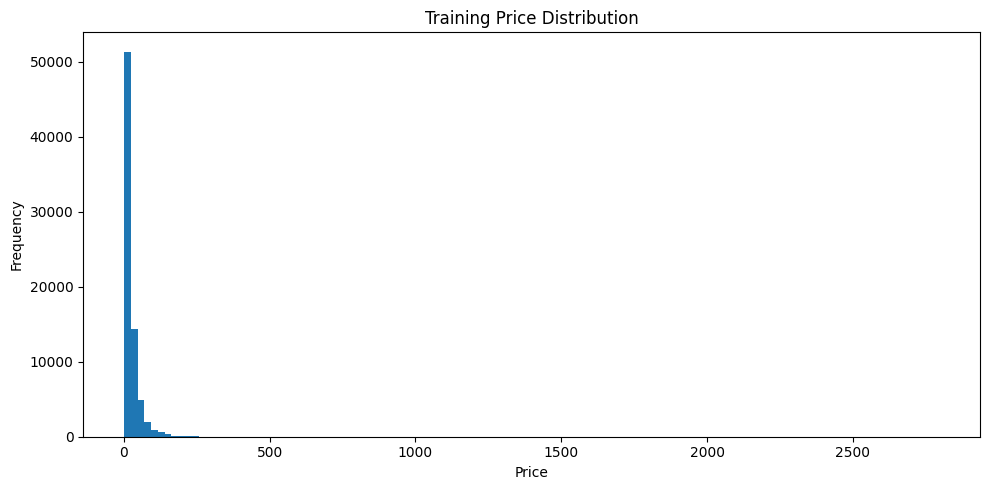

In [6]:
plt.figure(figsize=(10,5))
plt.hist(price, bins=120)
plt.title('Training Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


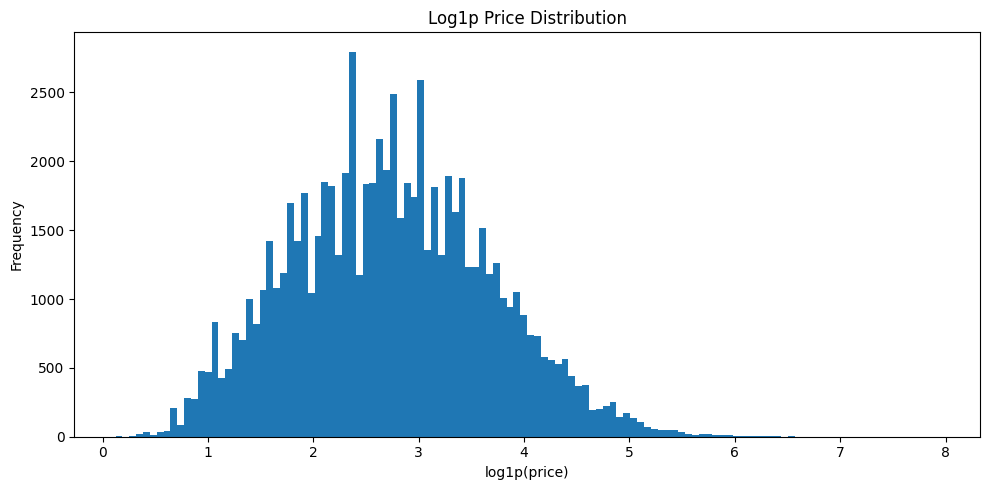

Raw price skew: 13.6014
Log price skew: 0.2039


In [7]:
train_df['log_price'] = np.log1p(train_df['price'])
plt.figure(figsize=(10,5))
plt.hist(train_df['log_price'], bins=120)
plt.title('Log1p Price Distribution')
plt.xlabel('log1p(price)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'log_price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Raw price skew:', round(train_df['price'].skew(),4))
print('Log price skew:', round(train_df['log_price'].skew(),4))


## 6. Price Buckets

In [8]:
price_bins=[0,5,10,25,50,100,250,np.inf]
price_labels=['$0–5','$5–10','$10–25','$25–50','$50–100','$100–250','$250+']
train_df['price_bucket']=pd.cut(train_df['price'],bins=price_bins,labels=price_labels,right=False,include_lowest=True)
price_bucket_summary=(train_df.groupby('price_bucket',observed=False)
    .agg(product_count=('sample_id','count'),median_price=('price','median'),mean_price=('price','mean')).reset_index())
price_bucket_summary['percentage']=(price_bucket_summary['product_count']/len(train_df)*100).round(2)
display(price_bucket_summary)
price_bucket_summary.to_csv(EDA_DIR/'price_bucket_summary.csv',index=False)


,price_bucket,product_count,median_price,mean_price,percentage
0,$0–5,13077,3.290,3.202822,17.44
1,$5–10,15435,7.490,7.535767,20.58
2,$10–25,24764,15.850,16.469365,33.02
3,$25–50,13616,33.990,35.086643,18.15
4,$50–100,6215,64.990,68.287315,8.29
5,$100–250,1741,130.050,141.177096,2.32
6,$250+,152,321.285,392.066513,0.20


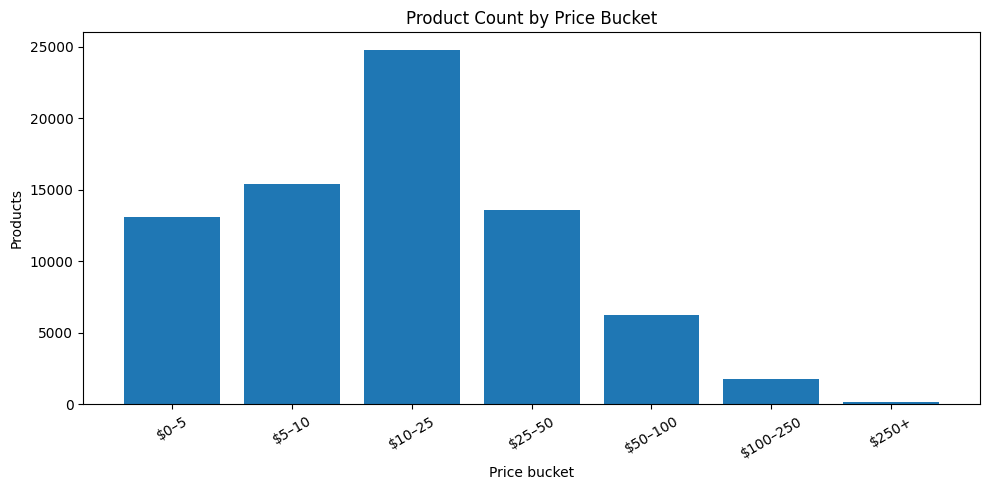

In [9]:
plt.figure(figsize=(10,5))
plt.bar(price_bucket_summary['price_bucket'].astype(str),price_bucket_summary['product_count'])
plt.title('Product Count by Price Bucket')
plt.xlabel('Price bucket')
plt.ylabel('Products')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR/'price_bucket_counts.png',dpi=150,bbox_inches='tight')
plt.show()


## 7. Outlier Diagnostics

In [10]:
q1=train_df['price'].quantile(0.25)
q3=train_df['price'].quantile(0.75)
iqr=q3-q1
upper_bound=q3+1.5*iqr
iqr_outliers=train_df[train_df['price']>upper_bound]
print('Q1:',q1)
print('Q3:',q3)
print('IQR:',iqr)
print('Upper IQR bound:',upper_bound)
print('High-price IQR outliers:',len(iqr_outliers))
print('Outlier percentage:',round(len(iqr_outliers)/len(train_df)*100,2),'%')
display(train_df.nlargest(25,'price')[['sample_id','price','catalog_content','image_link']])


Q1: 6.795
Q3: 28.625
IQR: 21.83
Upper IQR bound: 61.37
High-price IQR outliers: 5524
Outlier percentage: 7.37 %


,sample_id,price,catalog_content,image_link
58617,229126,2796.000,"Item Name: 4Patriots 1-Year Survival Food Kit: Emergency Food Supply Designed to Last 25 Years, 2,752 Servings\nBullet Point 1: 2,752 EMERGENCY FOOD SERVINGS: 24 delicious survival food recipes li...",https://m.media-amazon.com/images/I/81WiVwz7KkL.jpg
32153,134909,1280.000,"Item Name: Royal Amber Osetra Caviar - Russian Sturgeon Roe - Giaveri Italian (16 ounce (450 grams))\nBullet Point 1: Grade #1 , malossol cured, high quality sturgeon roe\nBullet Point 2: Acipense...",https://m.media-amazon.com/images/I/31fGy7wOV7L.jpg
22839,62251,1188.000,Item Name: 495 days proteins meal 33 bottles x180 food 25 years shelf life gluten free none GMO 5940 delicious meal tablets Vanilla\nBullet Point 1: Food proteins meal backup for the situations su...,https://m.media-amazon.com/images/I/71z7pFftrIL.jpg
46301,195806,1010.540,"Item Name: China Beauty Rings Tea (Loose) (8 oz, ZIN: 510605) - 2 Pack\nBullet Point 1: China Beauty Rings Tea (Loose) (8 oz, ZIN: 510605)\nBullet Point 2: No fillers.\nBullet Point 3: Manufacture...",https://m.media-amazon.com/images/I/81xJvPGH3YL.jpg
68388,236048,921.500,"Item Name: Organic Pistachios Shelled Raw, 30 Lbs. Bulk Case, Kosher\nBullet Point 1: USDA Organic Pistachios\nBullet Point 2: Kosher Parve (O-K)\nBullet Point 3: FSSC 22000 Certified Facility\nVa...",https://m.media-amazon.com/images/I/81eC194y1zL.jpg
72853,262694,779.250,"Item Name: Numanna Family Pack Bucket 432 Servings Easy Prep Survival Meals Emergency Food Supply Everyday Meals Camping Food Non-Gmo, No Added Preservatives Made in USA 25+ Year Shelf Life Long T...",https://m.media-amazon.com/images/I/812s9xubmAL.jpg
73067,190026,739.990,"Item Name: Crystal Geyser Pallet Of 84 Cases, Of Alpine 100% Natural Spring Water, 24 16.9oz bottles per Case, Bottled at The Source\nBullet Point 1: SIZE: Pallet of 84 Cases of 24-Bottle Cases, T...",https://m.media-amazon.com/images/I/A1Th9c7NqNL.jpg
45580,272914,691.160,"Item Name: Topps Juicy Drop Pop, 18 count per pack -- 16 per case.\nProduct Description: Topps Juicy Drop Pop, 18 count per pack -- 16 per case. 0.92 Ounce, Laydown Box\nValue: 16.0\nUnit: Count\n",https://m.media-amazon.com/images/I/71pIYhTtyoL.jpg
56075,227791,679.920,Item Name: Alex's Low Acid Organic Coffee Ultimate 5lb Bag Variety Pack\nBullet Point 1: These certified USDA organic premium coffee beans are specially processed to contain low to no chlorogenic ...,https://m.media-amazon.com/images/I/71Sh7ZJS6FL.jpg
4146,46413,613.580,Item Name: Beverage/Topping Heated Condiment Dispenser from Benchmark #21011\nBullet Point 1: 5 Quart Capacity\nBullet Point 2: Clear Polycarbonate Bowl\nBullet Point 3: 1100 Watts\nBullet Point 4...,https://m.media-amazon.com/images/I/31KD8rW9uNL.jpg


## 8. Basic Text Features

In [11]:
def add_basic_text_features(df):
    text=df['catalog_content'].fillna('').astype(str)
    df=df.copy()
    df['catalog_char_count']=text.str.len()
    df['catalog_word_count']=text.str.split().str.len()
    df['catalog_digit_count']=text.str.count(r'\d')
    df['catalog_line_count']=text.str.count(r'\n')+1
    df['bullet_count']=text.str.count(r'(?i)Bullet Point')
    df['numeric_token_count']=text.str.count(r'\b\d+(?:\.\d+)?\b')
    return df

train_df=add_basic_text_features(train_df)
test_df=add_basic_text_features(test_df)
feature_cols=['catalog_char_count','catalog_word_count','catalog_digit_count','catalog_line_count','bullet_count','numeric_token_count']
display(train_df[feature_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
catalog_char_count,75000.0,908.886547,852.896151,32.0,251.0,643.0,1280.0,7894.0
catalog_word_count,75000.0,147.851693,137.068731,7.0,42.0,104.0,208.0,1333.0
catalog_digit_count,75000.0,14.533027,8.603863,0.0,8.0,13.0,19.0,262.0
catalog_line_count,75000.0,8.002773,2.340287,4.0,6.0,9.0,10.0,31.0
bullet_count,75000.0,3.569027,2.233997,0.0,1.0,5.0,5.0,26.0
numeric_token_count,75000.0,8.384027,4.887651,0.0,5.0,8.0,11.0,85.0


## 9. Train/Test Distribution Comparison

In [12]:
rows=[]
for col in feature_cols:
    rows.append({'feature':col,'train_mean':train_df[col].mean(),'test_mean':test_df[col].mean(),
                 'train_median':train_df[col].median(),'test_median':test_df[col].median(),
                 'train_std':train_df[col].std(),'test_std':test_df[col].std()})
train_test_feature_summary=pd.DataFrame(rows)
display(train_test_feature_summary)
train_test_feature_summary.to_csv(EDA_DIR/'train_test_feature_summary.csv',index=False)


,feature,train_mean,test_mean,train_median,test_median,train_std,test_std
0,catalog_char_count,908.886547,910.762947,643.0,636.0,852.896151,857.030190
1,catalog_word_count,147.851693,148.145907,104.0,103.0,137.068731,137.760572
2,catalog_digit_count,14.533027,14.527320,13.0,13.0,8.603863,8.512676
3,catalog_line_count,8.002773,7.991533,9.0,9.0,2.340287,2.337090
4,bullet_count,3.569027,3.555187,5.0,5.0,2.233997,2.228795
5,numeric_token_count,8.384027,8.373720,8.0,8.0,4.887651,4.884626


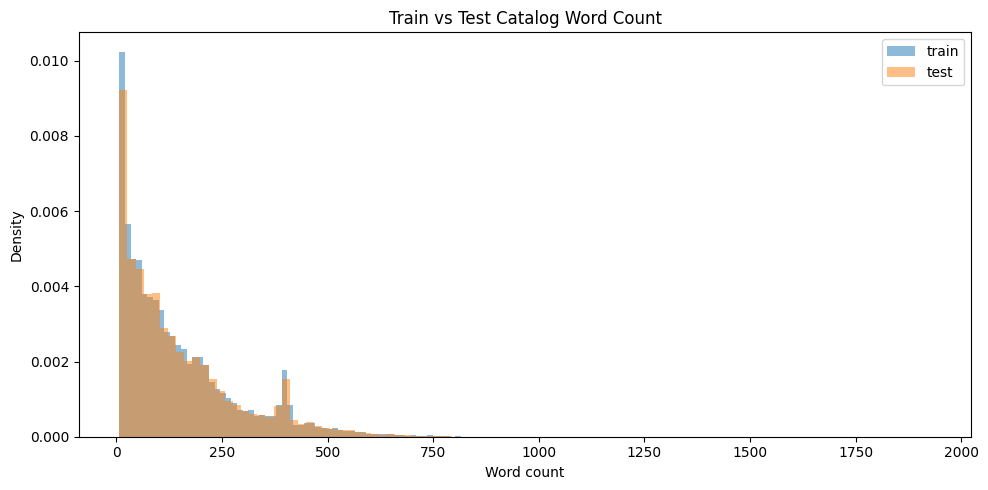

In [13]:
plt.figure(figsize=(10,5))
plt.hist(train_df['catalog_word_count'],bins=100,alpha=0.5,density=True,label='train')
plt.hist(test_df['catalog_word_count'],bins=100,alpha=0.5,density=True,label='test')
plt.title('Train vs Test Catalog Word Count')
plt.xlabel('Word count')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR/'train_test_word_count.png',dpi=150,bbox_inches='tight')
plt.show()


## 10. Parse Structured Catalog Fields

In [14]:
def extract_first_match(text,pattern,flags=re.IGNORECASE|re.MULTILINE):
    if pd.isna(text): return None
    m=re.search(pattern,str(text),flags)
    return m.group(1).strip() if m else None

def extract_item_name(text):
    return extract_first_match(text,r'^Item Name:\s*(.+)$')

def extract_value(text):
    raw=extract_first_match(text,r'^Value:\s*([^\n\r]+)$')
    if raw is None or raw.strip().lower() in {'nan','none',''}: return np.nan
    try: return float(raw.strip())
    except ValueError: return np.nan

def extract_unit(text):
    raw=extract_first_match(text,r'^Unit:\s*([^\n\r]+)$')
    if raw is None or raw.strip().lower() in {'nan','none',''}: return None
    return raw.strip()

for df in (train_df,test_df):
    df['item_name']=df['catalog_content'].map(extract_item_name)
    df['value']=df['catalog_content'].map(extract_value)
    df['unit']=df['catalog_content'].map(extract_unit)

display(train_df[['catalog_content','item_name','value','unit']].head(10))


,catalog_content,item_name,value,unit
0,"Item Name: La Victoria Green Taco Sauce Mild, 12 Ounce (Pack of 6)\nValue: 72.0\nUnit: Fl Oz\n","La Victoria Green Taco Sauce Mild, 12 Ounce (Pack of 6)",72.00,Fl Oz
1,"Item Name: Salerno Cookies, The Original Butter Cookies, 8 Ounce (Pack of 4)\nBullet Point 1: Original Butter Cookies: Classic butter cookies made with real butter\nBullet Point 2: Variety Pack: I...","Salerno Cookies, The Original Butter Cookies, 8 Ounce (Pack of 4)",32.00,Ounce
2,"Item Name: Bear Creek Hearty Soup Bowl, Creamy Chicken with Rice, 1.9 Ounce (Pack of 6)\nBullet Point 1: Loaded with hearty long grain wild rice and vegetables\nBullet Point 2: Full of hearty good...","Bear Creek Hearty Soup Bowl, Creamy Chicken with Rice, 1.9 Ounce (Pack of 6)",11.40,Ounce
3,"Item Name: Judee’s Blue Cheese Powder 11.25 oz - Gluten-Free and Nut-Free - Use in Seasonings and Salad Dressings - Great for Dips, Spreads and Sauces - Made in USA\nBullet Point 1: Add to your fa...","Judee’s Blue Cheese Powder 11.25 oz - Gluten-Free and Nut-Free - Use in Seasonings and Salad Dressings - Great for Dips, Spreads and Sauces - Made in USA",11.25,Ounce
4,"Item Name: kedem Sherry Cooking Wine, 12.7 Ounce - 12 per case.\nBullet Point: kedem Sherry Cooking Wine, 12.7 Ounce - 12 per case.\nValue: 12.0\nUnit: Count\n","kedem Sherry Cooking Wine, 12.7 Ounce - 12 per case.",12.00,Count
5,"Item Name: Member's Mark Member's Mark, Basil, 6.25 oz\nBullet Point 1: Green Herb, Italian Staple, Great mixed with Oregano\nBullet Point 2: Large Size, Chef Bottle\nBullet Point 3: Packed in the...","Member's Mark Member's Mark, Basil, 6.25 oz",6.25,ounce
6,"Item Name: Goya Foods Sazonador Total Seasoning, 30 Ounce (Pack of 6)\nBullet Point 1: SAZONADOR TOTAL | Enhance the natural flavors of food with the perfect mix of natural ingredients, Goya Sazon...","Goya Foods Sazonador Total Seasoning, 30 Ounce (Pack of 6)",180.00,Ounce
7,Item Name: VineCo Original Series Chilean Sauvignon Blanc Wine Making Ingredient Kit\nBullet Point 1: Chilean Sauvignon Blanc Wine Kit - VineCo Original Series\nBullet Point 2: Flavor Profile - He...,VineCo Original Series Chilean Sauvignon Blanc Wine Making Ingredient Kit,1.00,Count
8,"Item Name: NATURES PATH CEREAL FLK MULTIGRAIN ORG ECO, 32 OZ, PK- 6\nValue: 192.0\nUnit: Fl Oz\n","NATURES PATH CEREAL FLK MULTIGRAIN ORG ECO, 32 OZ, PK- 6",192.00,Fl Oz
9,Item Name: Mrs. Miller's Seedless Black Raspberry Jam 9 Ounce (Pack of 4)\nBullet Point 1: Homemade Seedless Black Raspberry Jam made from the finest ripened black raspberries\nBullet Point 2: Han...,Mrs. Miller's Seedless Black Raspberry Jam 9 Ounce (Pack of 4),9.00,Ounce


## 11. Structured Field Coverage

In [15]:
coverage=pd.DataFrame({
    'field':['item_name','value','unit'],
    'train_present':[train_df['item_name'].notna().sum(),train_df['value'].notna().sum(),train_df['unit'].notna().sum()],
    'test_present':[test_df['item_name'].notna().sum(),test_df['value'].notna().sum(),test_df['unit'].notna().sum()]})
coverage['train_pct']=(coverage['train_present']/len(train_df)*100).round(2)
coverage['test_pct']=(coverage['test_present']/len(test_df)*100).round(2)
display(coverage)


,field,train_present,test_present,train_pct,test_pct
0,item_name,74993,74992,99.99,99.99
1,value,74060,73989,98.75,98.65
2,unit,74059,73989,98.75,98.65


## 12. Pack Quantity Extraction

In [16]:
PACK_PATTERNS=[r'(?i)pack\s+of\s+(\d+)',r'(?i)(\d+)\s*[- ]?pack\b',r'(?i)(\d+)\s+per\s+case\b',r'(?i)case\s+of\s+(\d+)',r'(?i)set\s+of\s+(\d+)']

def extract_pack_quantity(text):
    text='' if pd.isna(text) else str(text)
    for pattern in PACK_PATTERNS:
        m=re.search(pattern,text)
        if m:
            v=int(m.group(1))
            if 1<=v<=500: return v
    return 1

train_df['pack_quantity']=train_df['catalog_content'].map(extract_pack_quantity)
test_df['pack_quantity']=test_df['catalog_content'].map(extract_pack_quantity)
display(train_df['pack_quantity'].describe())
display(train_df['pack_quantity'].value_counts().head(20).to_frame('count'))


count    75000.000000
mean         4.517027
std         15.115916
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        500.000000
Name: pack_quantity, dtype: float64

,count
pack_quantity,
1,48008
6,5558
12,5077
2,4475
3,3821
4,2308
24,1219
8,1095
10,565


## 13. Pack Quantity vs Price

In [17]:
pack_summary=(train_df.groupby('pack_quantity')
    .agg(product_count=('sample_id','count'),median_price=('price','median'),mean_price=('price','mean'))
    .reset_index().sort_values('product_count',ascending=False))
display(pack_summary.head(25))
pack_summary.to_csv(EDA_DIR/'pack_quantity_summary.csv',index=False)


,pack_quantity,product_count,median_price,mean_price
0,1,48008,12.9900,20.883376
5,6,5558,16.4925,26.832379
11,12,5077,16.4800,26.973791
1,2,4475,19.0900,28.361947
2,3,3821,19.1200,31.634921
3,4,2308,13.6000,24.779872
23,24,1219,18.1850,27.806669
7,8,1095,9.0900,21.291009
9,10,565,14.4500,27.427717
4,5,462,11.3600,19.560292


## 14. Unit Analysis

In [18]:
def normalize_unit(unit):
    if pd.isna(unit): return None
    u=str(unit).strip().lower()
    replacements={'fluid ounce':'fl oz','fluid ounces':'fl oz','fl. oz.':'fl oz','ounces':'ounce','oz':'ounce',
                  'pounds':'pound','lbs':'pound','lb':'pound','grams':'gram','g':'gram','kilograms':'kilogram','kg':'kilogram',
                  'liters':'liter','litres':'liter','milliliters':'milliliter','ml':'milliliter','counts':'count'}
    return replacements.get(u,u)

train_df['unit_normalized']=train_df['unit'].map(normalize_unit)
test_df['unit_normalized']=test_df['unit'].map(normalize_unit)
unit_summary=(train_df.groupby('unit_normalized',dropna=False)
    .agg(product_count=('sample_id','count'),median_price=('price','median'),mean_price=('price','mean'),median_value=('value','median'))
    .reset_index().sort_values('product_count',ascending=False))
display(unit_summary.head(30))
unit_summary.to_csv(EDA_DIR/'unit_summary.csv',index=False)


,unit_normalized,product_count,median_price,mean_price,median_value
37,ounce,44028,12.9900,21.377643,16.000
15,count,18214,18.5100,29.938708,10.000
19,fl oz,11309,11.9900,21.063113,32.000
53,NaN,941,14.5000,35.489160,1.000
46,pound,240,25.2100,39.927354,4.000
16,ct,49,7.6900,11.894898,12.000
25,gram,42,11.0350,16.373452,157.500
17,each,21,12.9900,19.566190,6.720
20,fl. oz,21,10.7150,29.337619,16.000
39,packs,12,25.7900,44.685000,14.000


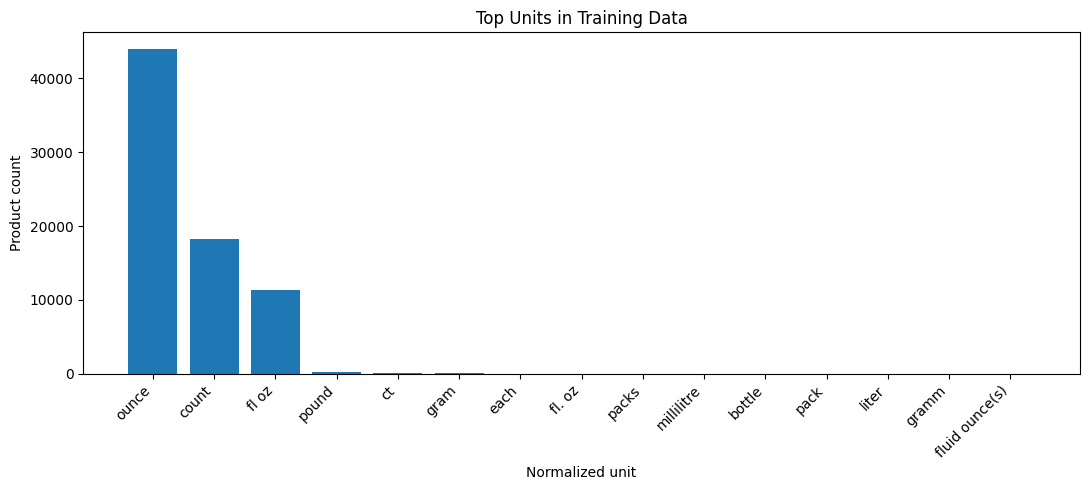

In [19]:
top_units=unit_summary[unit_summary['unit_normalized'].notna()].head(15)
plt.figure(figsize=(11,5))
plt.bar(top_units['unit_normalized'].astype(str),top_units['product_count'])
plt.title('Top Units in Training Data')
plt.xlabel('Normalized unit')
plt.ylabel('Product count')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.savefig(FIGURES_DIR/'top_units.png',dpi=150,bbox_inches='tight')
plt.show()


## 15. Numeric Feature Relationships with Price

In [20]:
numeric_features=['catalog_char_count','catalog_word_count','catalog_digit_count','catalog_line_count','bullet_count','numeric_token_count','value','pack_quantity','price','log_price']
corr=train_df[numeric_features].corr(method='spearman')
display(corr.round(3))
corr.to_csv(EDA_DIR/'numeric_spearman_correlations.csv')
price_corr=corr['price'].drop(labels=['price']).sort_values(key=lambda s:s.abs(),ascending=False).to_frame('spearman_with_price')
display(price_corr)


,catalog_char_count,catalog_word_count,catalog_digit_count,catalog_line_count,bullet_count,numeric_token_count,value,pack_quantity,price,log_price
catalog_char_count,1.000,0.998,0.686,0.831,0.755,0.744,0.010,-0.043,0.258,0.258
catalog_word_count,0.998,1.000,0.690,0.831,0.758,0.751,0.015,-0.034,0.254,0.254
catalog_digit_count,0.686,0.690,1.000,0.707,0.683,0.917,0.193,0.135,0.191,0.191
catalog_line_count,0.831,0.831,0.707,1.000,0.929,0.802,-0.012,-0.051,0.173,0.173
bullet_count,0.755,0.758,0.683,0.929,1.000,0.794,0.024,-0.031,0.094,0.094
numeric_token_count,0.744,0.751,0.917,0.802,0.794,1.000,0.099,0.116,0.174,0.174
value,0.010,0.015,0.193,-0.012,0.024,0.099,1.000,0.362,0.154,0.154
pack_quantity,-0.043,-0.034,0.135,-0.051,-0.031,0.116,0.362,1.000,0.097,0.097
price,0.258,0.254,0.191,0.173,0.094,0.174,0.154,0.097,1.000,1.000
log_price,0.258,0.254,0.191,0.173,0.094,0.174,0.154,0.097,1.000,1.000


,spearman_with_price
log_price,1.000000
catalog_char_count,0.258015
catalog_word_count,0.253663
catalog_digit_count,0.190998
numeric_token_count,0.173999
catalog_line_count,0.172904
value,0.153654
pack_quantity,0.096502
bullet_count,0.094200


## 16. Price vs Catalog Length

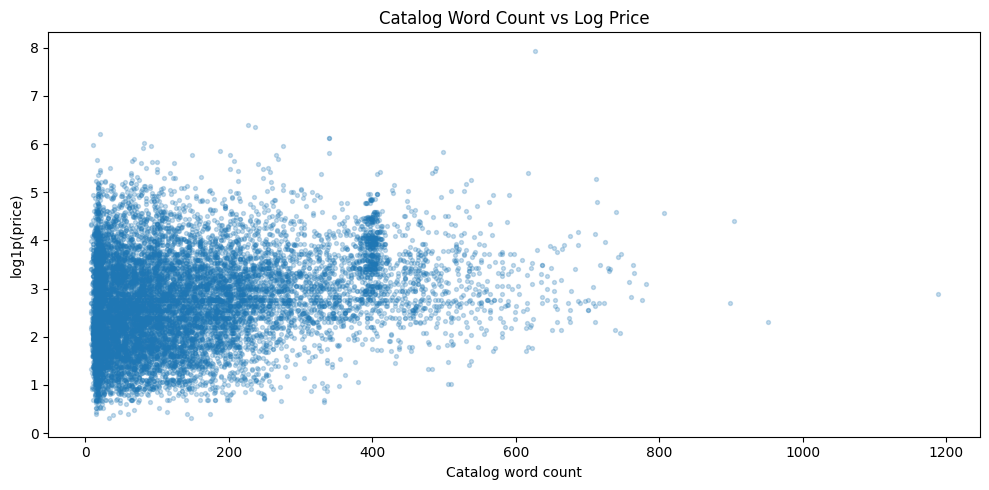

In [21]:
sample_for_plot=train_df.sample(min(12000,len(train_df)),random_state=42)
plt.figure(figsize=(10,5))
plt.scatter(sample_for_plot['catalog_word_count'],sample_for_plot['log_price'],s=8,alpha=0.25)
plt.title('Catalog Word Count vs Log Price')
plt.xlabel('Catalog word count')
plt.ylabel('log1p(price)')
plt.tight_layout()
plt.savefig(FIGURES_DIR/'word_count_vs_log_price.png',dpi=150,bbox_inches='tight')
plt.show()


## 17. Duplicate Catalog Analysis

In [22]:
duplicate_catalog_rows=train_df[train_df.duplicated('catalog_content',keep=False)].copy()
duplicate_catalog_summary=(duplicate_catalog_rows.groupby('catalog_content')
    .agg(row_count=('sample_id','count'),unique_prices=('price','nunique'),min_price=('price','min'),max_price=('price','max'),median_price=('price','median'),unique_images=('image_link','nunique'))
    .reset_index().sort_values(['unique_prices','row_count'],ascending=False))
print('Duplicate catalog groups:',len(duplicate_catalog_summary))
print('Groups with different prices:',(duplicate_catalog_summary['unique_prices']>1).sum())
display(duplicate_catalog_summary.head(25))
duplicate_catalog_summary.to_csv(EDA_DIR/'duplicate_catalog_summary.csv',index=False)


Duplicate catalog groups: 93
Groups with different prices: 67


,catalog_content,row_count,unique_prices,min_price,max_price,median_price,unique_images
60,"Item Name: PAPYRUS Everyday Card, 1 EA\nValue: 1.0\nUnit: Count\n",5,4,12.000,16.990,15.9900,5
26,Item Name: Eden Foods Salt Gomasio Ssme Seawd\nValue: 1.0\nUnit: Count\n,3,3,9.860,10.990,10.6950,3
31,"Item Name: French's White Cheddar Crispy Fried Onions, 6 oz\nBullet Point 1: Made with real onions\nBullet Point 2: White cheddar and onion-flavored topping with a crispy, crunchy texture\nBullet ...",3,3,5.190,26.960,5.6900,2
59,"Item Name: PAPYRUS Everyday Card, 1 EA\nProduct Description: Lifestyle\nValue: 1.0\nUnit: Count\n",3,3,9.970,17.990,16.9900,3
68,"Item Name: Rose’s Sweetened Grenadine Syrup 25oz Bottle | Perfect for Cocktails, Beverages, and Mixers\nBullet Point 1: Grenadine: A rich, pomegranate flavor, sweetened for perfect mixability in y...",3,3,17.980,36.980,24.9800,3
3,"Item Name: AmazonFresh Hazelnut Flavored Coffee, Ground, Medium Roast, 12 Ounce\nBullet Point 1: Fragrant medium-light roast with toasted hazelnut flavor\nBullet Point 2: One 12-ounce bag of groun...",2,2,7.290,7.640,7.4650,1
5,"Item Name: Arrowhead Mills Organic Yellow Popcorn, 28 oz Bag\nBullet Point 1: 1 - 28 oz Bag of Arrowhead Mills Organic Yellow Popcorn\nBullet Point 2: Arrowhead Mills Organic Yellow Popcorn is a c...",2,2,4.590,7.990,6.2900,1
7,"Item Name: BARNEY BUTTER NUT BTTR ALMND CRNCHY, 16 OZ\nValue: 16.0\nUnit: Fl Oz\n",2,2,12.490,14.055,13.2725,2
12,Item Name: Big Train Blended Ice Coffee - 3.5 lb bags - Case of 4 - Single Flavor\nValue: 224.0\nUnit: Ounce\n,2,2,29.270,31.745,30.5075,2
13,"Item Name: Blooms2Door 100 Red Roses (Farm-Fresh, Long Stem - 50cm) - Farm Direct Wholesale Fresh Flowers\nValue: 100.0\nUnit: Count\n",2,2,71.670,320.450,196.0600,2


## 18. Inspect Duplicate Catalogs with Different Prices

In [23]:
conflicting_catalogs=duplicate_catalog_summary.loc[duplicate_catalog_summary['unique_prices']>1,'catalog_content'].head(10)
if len(conflicting_catalogs):
    display(duplicate_catalog_rows[duplicate_catalog_rows['catalog_content'].isin(conflicting_catalogs)][['sample_id','price','image_link','catalog_content']].sort_values('catalog_content'))
else:
    print('No duplicate catalog-content groups with conflicting prices found.')


,sample_id,price,image_link,catalog_content
11795,185463,7.290,https://m.media-amazon.com/images/I/81w29mbZOtL.jpg,"Item Name: AmazonFresh Hazelnut Flavored Coffee, Ground, Medium Roast, 12 Ounce\nBullet Point 1: Fragrant medium-light roast with toasted hazelnut flavor\nBullet Point 2: One 12-ounce bag of groun..."
63885,188458,7.640,https://m.media-amazon.com/images/I/81w29mbZOtL.jpg,"Item Name: AmazonFresh Hazelnut Flavored Coffee, Ground, Medium Roast, 12 Ounce\nBullet Point 1: Fragrant medium-light roast with toasted hazelnut flavor\nBullet Point 2: One 12-ounce bag of groun..."
38335,292194,7.990,https://m.media-amazon.com/images/I/81i68BdOHnL.jpg,"Item Name: Arrowhead Mills Organic Yellow Popcorn, 28 oz Bag\nBullet Point 1: 1 - 28 oz Bag of Arrowhead Mills Organic Yellow Popcorn\nBullet Point 2: Arrowhead Mills Organic Yellow Popcorn is a c..."
35516,285994,4.590,https://m.media-amazon.com/images/I/81i68BdOHnL.jpg,"Item Name: Arrowhead Mills Organic Yellow Popcorn, 28 oz Bag\nBullet Point 1: 1 - 28 oz Bag of Arrowhead Mills Organic Yellow Popcorn\nBullet Point 2: Arrowhead Mills Organic Yellow Popcorn is a c..."
70793,38670,12.490,https://m.media-amazon.com/images/I/21PTrpTgF4L.jpg,"Item Name: BARNEY BUTTER NUT BTTR ALMND CRNCHY, 16 OZ\nValue: 16.0\nUnit: Fl Oz\n"
32078,42037,14.055,https://m.media-amazon.com/images/I/11AGY979GyL.jpg,"Item Name: BARNEY BUTTER NUT BTTR ALMND CRNCHY, 16 OZ\nValue: 16.0\nUnit: Fl Oz\n"
73749,107640,29.270,https://m.media-amazon.com/images/I/61n56m0cfML.jpg,Item Name: Big Train Blended Ice Coffee - 3.5 lb bags - Case of 4 - Single Flavor\nValue: 224.0\nUnit: Ounce\n
35107,107612,31.745,https://m.media-amazon.com/images/I/61M3tl7ubDL.jpg,Item Name: Big Train Blended Ice Coffee - 3.5 lb bags - Case of 4 - Single Flavor\nValue: 224.0\nUnit: Ounce\n
3157,149071,320.450,https://m.media-amazon.com/images/I/81C4XICOW-L.jpg,"Item Name: Blooms2Door 100 Red Roses (Farm-Fresh, Long Stem - 50cm) - Farm Direct Wholesale Fresh Flowers\nValue: 100.0\nUnit: Count\n"
34041,183295,71.670,https://m.media-amazon.com/images/I/91H+qdgUWGL.jpg,"Item Name: Blooms2Door 100 Red Roses (Farm-Fresh, Long Stem - 50cm) - Farm Direct Wholesale Fresh Flowers\nValue: 100.0\nUnit: Count\n"


## 19. Image Filename and Reuse Analysis

In [24]:
def filename_from_url(url):
    if pd.isna(url): return None
    return Path(urlparse(str(url)).path).name

train_df['image_filename']=train_df['image_link'].map(filename_from_url)
test_df['image_filename']=test_df['image_link'].map(filename_from_url)
train_image_counts=train_df['image_filename'].value_counts()
test_image_counts=test_df['image_filename'].value_counts()
image_reuse_summary=pd.DataFrame({'metric':['train rows','train unique image filenames','train reused image filenames','max train rows per image','test rows','test unique image filenames','test reused image filenames','max test rows per image'],
'value':[len(train_df),train_df['image_filename'].nunique(),int((train_image_counts>1).sum()),int(train_image_counts.max()),len(test_df),test_df['image_filename'].nunique(),int((test_image_counts>1).sum()),int(test_image_counts.max())]})
display(image_reuse_summary)
image_reuse_summary.to_csv(EDA_DIR/'image_reuse_summary.csv',index=False)


,metric,value
0,train rows,75000
1,train unique image filenames,72288
2,train reused image filenames,2175
3,max train rows per image,52
4,test rows,75000
5,test unique image filenames,72222
6,test reused image filenames,2233
7,max test rows per image,45


## 20. Train/Test Shared Images

In [25]:
train_images_set=set(train_df['image_filename'].dropna())
test_images_set=set(test_df['image_filename'].dropna())
shared_images=train_images_set.intersection(test_images_set)
print('Unique train image filenames:',len(train_images_set))
print('Unique test image filenames :',len(test_images_set))
print('Shared image filenames      :',len(shared_images))
print('Shared / test unique (%)    :',round(len(shared_images)/max(len(test_images_set),1)*100,2))


Unique train image filenames: 72288
Unique test image filenames : 72222
Shared image filenames      : 3923
Shared / test unique (%)    : 5.43


## 21. Local Image Coverage Recheck

In [26]:
IMAGE_EXTENSIONS={'.jpg','.jpeg','.png','.webp'}
train_local_names={p.name for p in TRAIN_IMAGE_DIR.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS}
test_local_names={p.name for p in TEST_IMAGE_DIR.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS}
train_df['local_image_exists']=train_df['image_filename'].isin(train_local_names)
test_df['local_image_exists']=test_df['image_filename'].isin(test_local_names)
print('Train mapped rows:',train_df['local_image_exists'].sum(),'/',len(train_df))
print('Test mapped rows :',test_df['local_image_exists'].sum(),'/',len(test_df))


Train mapped rows: 74999 / 75000
Test mapped rows : 74999 / 75000


## 22. Value Distribution

Training rows with parsed Value: 74060


count    74060.000000
mean        54.306073
std        461.818743
min          0.000000
1%           0.750000
5%           1.000000
50%         16.000000
95%        192.000000
99%        432.000000
max      63882.000000
Name: value, dtype: float64

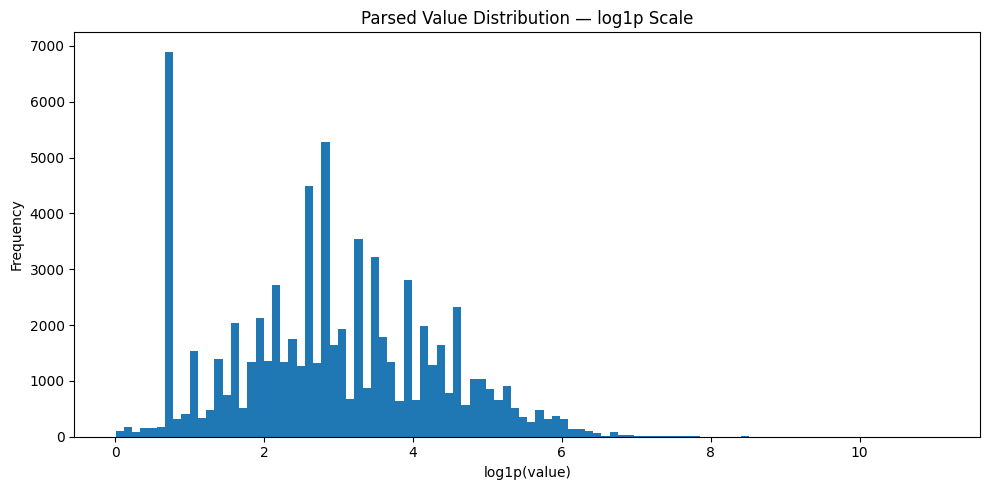

In [27]:
print('Training rows with parsed Value:',train_df['value'].notna().sum())
display(train_df['value'].describe(percentiles=[0.01,0.05,0.50,0.95,0.99]))
value_plot_df=train_df[(train_df['value'].notna())&(train_df['value']>0)].copy()
value_plot_df['log_value']=np.log1p(value_plot_df['value'])
plt.figure(figsize=(10,5))
plt.hist(value_plot_df['log_value'],bins=100)
plt.title('Parsed Value Distribution — log1p Scale')
plt.xlabel('log1p(value)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(FIGURES_DIR/'parsed_value_distribution.png',dpi=150,bbox_inches='tight')
plt.show()


## 23. Price by Common Unit

,unit_normalized,product_count,median_price,mean_price
0,ounce,44028,12.990,21.377643
1,count,18214,18.510,29.938708
2,fl oz,11309,11.990,21.063113
3,pound,240,25.210,39.927354
4,ct,49,7.690,11.894898
5,gram,42,11.035,16.373452
6,each,21,12.990,19.566190
7,fl. oz,21,10.715,29.337619
8,packs,12,25.790,44.685000
9,bottle,9,10.590,13.664444


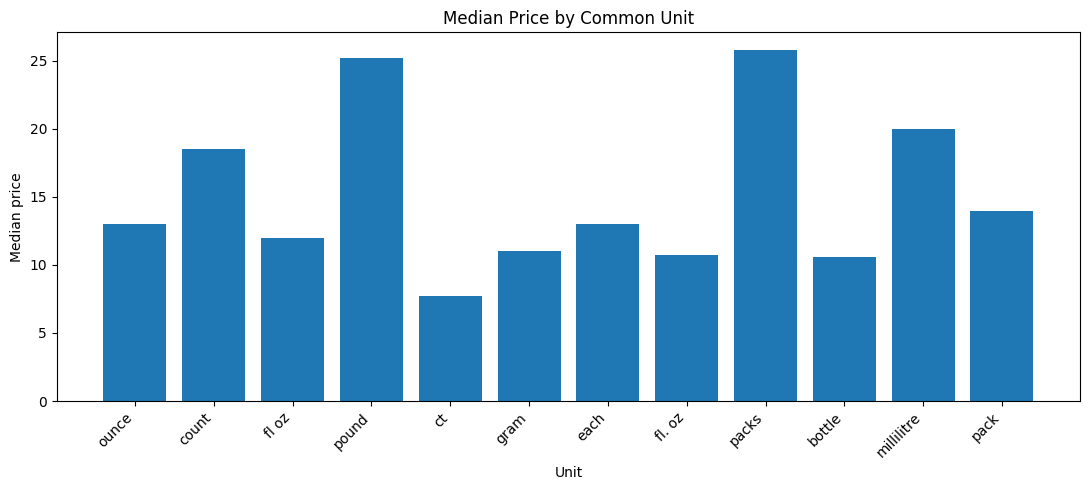

In [28]:
common_units=train_df['unit_normalized'].value_counts().head(12).index
common_unit_price=(train_df[train_df['unit_normalized'].isin(common_units)].groupby('unit_normalized')
    .agg(product_count=('sample_id','count'),median_price=('price','median'),mean_price=('price','mean'))
    .sort_values('product_count',ascending=False).reset_index())
display(common_unit_price)
plt.figure(figsize=(11,5))
plt.bar(common_unit_price['unit_normalized'].astype(str),common_unit_price['median_price'])
plt.title('Median Price by Common Unit')
plt.xlabel('Unit')
plt.ylabel('Median price')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.savefig(FIGURES_DIR/'median_price_by_unit.png',dpi=150,bbox_inches='tight')
plt.show()


## 24. Cheapest and Most Expensive Products

In [29]:
print('20 cheapest products')
display(train_df.nsmallest(20,'price')[['sample_id','price','item_name','value','unit_normalized','pack_quantity']])
print('20 most expensive products')
display(train_df.nlargest(20,'price')[['sample_id','price','item_name','value','unit_normalized','pack_quantity']])


20 cheapest products


,sample_id,price,item_name,value,unit_normalized,pack_quantity
1774,261551,0.130,"Merci European Chocolates, 7 Ounce (Pack of 10)",70.00,ounce,10
32750,212063,0.130,"Frank's RedHot Squeeze Sriracha Sauce, 1.7 fl oz (Pack of 24)",40.80,fl oz,24
66444,144562,0.300,"Maruchan Ramen Noodle Soup, Beef, 3 Ounce",3.00,ounce,1
6209,144673,0.330,"Maruchan Creamy Chicken Ramen Noodles, 3 oz",3.00,ounce,1
5982,25417,0.360,"Maruchan Ramen Beef, 0.1875-Ounce Packages (Pack of 24)",72.00,ounce,24
31076,86997,0.360,Kool-aid Watermelon Unsweetened 15 Packets,2.25,ounce,1
65384,298503,0.360,Kool Aid Grape - 3.9g,0.14,ounce,1
30124,137208,0.370,Kool-Aid Unsweetened Caffeine Free Watermelon Zero Calories Powdered Drink Mix 1 Count Pitcher Packet,0.15,ounce,1
69130,274726,0.370,"Maruchan Ramen Noodle Soup, Beef, 3 oz",3.00,ounce,1
74116,173321,0.370,"Kool Aid Watermelon Drink Mix, Makes 2 Quarts (0.15 oz Packets, Pack of 192)",28.80,ounce,192


20 most expensive products


,sample_id,price,item_name,value,unit_normalized,pack_quantity
58617,229126,2796.000,"4Patriots 1-Year Survival Food Kit: Emergency Food Supply Designed to Last 25 Years, 2,752 Servings",1.00,count,1
32153,134909,1280.000,Royal Amber Osetra Caviar - Russian Sturgeon Roe - Giaveri Italian (16 ounce (450 grams)),16.00,ounce,1
22839,62251,1188.000,495 days proteins meal 33 bottles x180 food 25 years shelf life gluten free none GMO 5940 delicious meal tablets Vanilla,33.00,count,1
46301,195806,1010.540,"China Beauty Rings Tea (Loose) (8 oz, ZIN: 510605) - 2 Pack",16.00,ounce,2
68388,236048,921.500,"Organic Pistachios Shelled Raw, 30 Lbs. Bulk Case, Kosher",480.00,ounce,1
72853,262694,779.250,"Numanna Family Pack Bucket 432 Servings Easy Prep Survival Meals Emergency Food Supply Everyday Meals Camping Food Non-Gmo, No Added Preservatives Made in USA 25+ Year Shelf Life Long Term Meal",3.00,count,1
73067,190026,739.990,"Crystal Geyser Pallet Of 84 Cases, Of Alpine 100% Natural Spring Water, 24 16.9oz bottles per Case, Bottled at The Source",34070.40,fl oz,1
45580,272914,691.160,"Topps Juicy Drop Pop, 18 count per pack -- 16 per case.",16.00,count,16
56075,227791,679.920,Alex's Low Acid Organic Coffee Ultimate 5lb Bag Variety Pack,640.00,ounce,1
4146,46413,613.580,Beverage/Topping Heated Condiment Dispenser from Benchmark #21011,1.00,count,1


## 25. Save Compact EDA Feature Tables

In [30]:
eda_feature_columns=['sample_id','catalog_char_count','catalog_word_count','catalog_digit_count','catalog_line_count','bullet_count','numeric_token_count','value','unit','unit_normalized','pack_quantity','image_filename','local_image_exists']
train_eda_features=train_df[eda_feature_columns+['price']].copy()
test_eda_features=test_df[eda_feature_columns].copy()
train_eda_features.to_csv(EDA_DIR/'train_eda_features.csv',index=False)
test_eda_features.to_csv(EDA_DIR/'test_eda_features.csv',index=False)
print('Saved:',EDA_DIR/'train_eda_features.csv')
print('Saved:',EDA_DIR/'test_eda_features.csv')


Saved: /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/artifacts/eda/train_eda_features.csv
Saved: /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/artifacts/eda/test_eda_features.csv


## 26. Save EDA Summary JSON

In [31]:
summary={
    'train_rows':int(len(train_df)),'test_rows':int(len(test_df)),
    'price_mean':float(train_df['price'].mean()),'price_median':float(train_df['price'].median()),
    'price_min':float(train_df['price'].min()),'price_max':float(train_df['price'].max()),
    'price_skew':float(train_df['price'].skew()),'log_price_skew':float(train_df['log_price'].skew()),
    'parsed_value_coverage_train_pct':float(train_df['value'].notna().mean()*100),
    'parsed_value_coverage_test_pct':float(test_df['value'].notna().mean()*100),
    'parsed_unit_coverage_train_pct':float(train_df['unit'].notna().mean()*100),
    'parsed_unit_coverage_test_pct':float(test_df['unit'].notna().mean()*100),
    'train_unique_image_filenames':int(train_df['image_filename'].nunique()),
    'test_unique_image_filenames':int(test_df['image_filename'].nunique()),
    'shared_train_test_image_filenames':int(len(shared_images)),
    'train_duplicate_catalog_groups':int(len(duplicate_catalog_summary)),
    'duplicate_catalog_groups_with_different_prices':int((duplicate_catalog_summary['unique_prices']>1).sum()),
    'train_missing_local_image_rows':int((~train_df['local_image_exists']).sum()),
    'test_missing_local_image_rows':int((~test_df['local_image_exists']).sum())}
summary_path=EDA_DIR/'eda_summary.json'
with summary_path.open('w') as f: json.dump(summary,f,indent=2)
print('Saved EDA summary:',summary_path)
display(pd.Series(summary,name='value').to_frame())


Saved EDA summary: /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/artifacts/eda/eda_summary.json


,value
train_rows,75000.000000
test_rows,75000.000000
price_mean,23.647654
price_median,14.000000
price_min,0.130000
price_max,2796.000000
price_skew,13.601389
log_price_skew,0.203924
parsed_value_coverage_train_pct,98.746667
parsed_value_coverage_test_pct,98.652000


## 27. V0.2 Final Summary

In [32]:
print('='*72)
print('PRICEFUSION V0.2 — DEEP EDA COMPLETE')
print('='*72)
print(f'Train rows                         : {len(train_df):,}')
print(f'Test rows                          : {len(test_df):,}')
print(f'Price median                       : {train_df["price"].median():.4f}')
print(f'Price maximum                      : {train_df["price"].max():.4f}')
print(f'Raw price skew                     : {train_df["price"].skew():.4f}')
print(f'Log-price skew                     : {train_df["log_price"].skew():.4f}')
print(f'Parsed Value coverage              : {train_df["value"].notna().mean()*100:.2f}%')
print(f'Parsed Unit coverage               : {train_df["unit"].notna().mean()*100:.2f}%')
print(f'Duplicate catalog groups           : {len(duplicate_catalog_summary):,}')
print(f'Duplicate groups w/ price conflict : {(duplicate_catalog_summary["unique_prices"]>1).sum():,}')
print(f'Shared train/test image filenames  : {len(shared_images):,}')
print(f'Train missing local image rows     : {(~train_df["local_image_exists"]).sum():,}')
print(f'Test missing local image rows      : {(~test_df["local_image_exists"]).sum():,}')
print('='*72)
print('Artifacts saved under artifacts/eda/ and artifacts/figures/.')
print('Next milestone: PriceFusion V0.3 — TF-IDF + Ridge Baseline')


PRICEFUSION V0.2 — DEEP EDA COMPLETE
Train rows                         : 75,000
Test rows                          : 75,000
Price median                       : 14.0000
Price maximum                      : 2796.0000
Raw price skew                     : 13.6014
Log-price skew                     : 0.2039
Parsed Value coverage              : 98.75%
Parsed Unit coverage               : 98.75%
Duplicate catalog groups           : 93
Duplicate groups w/ price conflict : 67
Shared train/test image filenames  : 3,923
Train missing local image rows     : 1
Test missing local image rows      : 1
Artifacts saved under artifacts/eda/ and artifacts/figures/.
Next milestone: PriceFusion V0.3 — TF-IDF + Ridge Baseline
